# Underwater Image Enhancement Training

Mô hình khởi tạo ngẫu nhiên, huấn luyện trên năm bộ dữ liệu có ảnh tham chiếu. VGG16 và CIDNet cung cấp đặc trưng pretrained cho hàm mất mát.

Train, validation và test được tách riêng. Ảnh không có GT trong Challenging-60, EUVP và U45 chỉ được kiểm kê.


## 1. Environment


In [1]:
from pathlib import Path
import os, sys, json, random, time, hashlib, math
import numpy as np
import pandas as pd
import torch
from torch.utils.data import ConcatDataset, DataLoader, Subset
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'AGENTS.md').is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
if str(ROOT / '.runtime') not in sys.path: sys.path.insert(0, str(ROOT / '.runtime'))
from model import myModel
from utils.dataset import DatasetFromFolder, is_image_file
from utils.loss_funcs import PerceptualLoss, L1_Charbonnier_loss, SSIMLoss, EdgeAwareLoss
from utils.CIDNet import CIDNet
from utils.metrics import Evaluator
from train import seed_everything, replace_with_retry

assert torch.cuda.is_available(), 'Cần GPU CUDA. Hãy chọn kernel demo trong Anaconda.'
DEVICE = torch.device('cuda')
torch.set_num_threads(1)
torch.hub.set_dir(str(ROOT / 'downloads/torch'))
print('Python:', sys.version.split()[0], '| executable:', sys.executable)
print('PyTorch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('GPU:', torch.cuda.get_device_name(0))
print('Project:', ROOT)


D:\xulyanh_ttnt1\UNDERWATER-IMAGING\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.9 | executable: D:\xulyanh_ttnt1\UNDERWATER-IMAGING\.venv\Scripts\python.exe
PyTorch: 2.7.1+cu128 | CUDA: 12.8
GPU: NVIDIA GeForce RTX 5060 Ti
Project: D:\xulyanh_ttnt1\UNDERWATER-IMAGING


## 2. Configuration


In [2]:
SEED = 7
EPOCHS = 100
BATCH_SIZE = 4
EFFECTIVE_BATCH = 24
IMAGE_SIZE = 256
LR = 2e-3
WEIGHT_DECAY = 1e-5
# Full checkpoint (checkpoints/epoch_XXX.pth or last_checkpoint.pth) to continue an interrupted run; None = fresh run.
RESUME_FROM = os.environ.get('TRAIN_RESUME_FROM') or None
DATA_ROOT = ROOT / 'UnderWaterDataset'
FOLDERS = ['EUVP-Dark', 'EUVP-Scene', 'LSUI', 'UFO-120', 'UIEB']
assert DATA_ROOT.is_dir(), f'Không tìm thấy dataset: {DATA_ROOT}'
assert EFFECTIVE_BATCH % BATCH_SIZE == 0
ACCUMULATION = EFFECTIVE_BATCH // BATCH_SIZE

# OS lock prevents accidentally starting a second notebook training job on this GPU.
import msvcrt
lock_path = ROOT / 'output/notebook_training.lock'
lock_path.parent.mkdir(exist_ok=True)
training_lock = open(lock_path, 'a+b')
if lock_path.stat().st_size == 0: training_lock.write(b'0'); training_lock.flush()
training_lock.seek(0)
try:
    msvcrt.locking(training_lock.fileno(), msvcrt.LK_NBLCK, 1)
except OSError:
    training_lock.close()
    raise RuntimeError('Một lượt notebook training đang chạy. Dừng lượt đó trước khi Run All lần nữa.')

if RESUME_FROM:
    RESUME_FROM = Path(RESUME_FROM).resolve()
    assert RESUME_FROM.is_file(), f'Không tìm thấy checkpoint: {RESUME_FROM}'
    RUN_DIR = RESUME_FROM.parent.parent if RESUME_FROM.parent.name == 'checkpoints' else RESUME_FROM.parent
else:
    RUN_DIR = ROOT / 'output/demo/ALL' / ('notebook_' + time.strftime('%Y%m%d_%H%M%S'))
    RUN_DIR.mkdir(parents=True, exist_ok=False)
CHECKPOINT_DIR = RUN_DIR / 'checkpoints'
CHECKPOINT_DIR.mkdir(exist_ok=True)
config = dict(seed=SEED, epochs=EPOCHS, batch_size=BATCH_SIZE, effective_batch=EFFECTIVE_BATCH,
              image_size=IMAGE_SIZE, lr=LR, weight_decay=WEIGHT_DECAY,
              datasets=FOLDERS, data_root=str(DATA_ROOT), initialization='random', resume=str(RESUME_FROM) if RESUME_FROM else None,
              torch=torch.__version__, gpu=torch.cuda.get_device_name(0),
              best_criterion='macro mean validation PSNR across the five paired datasets')
config_name = 'config.json' if not RESUME_FROM else 'config_resume_' + time.strftime('%Y%m%d_%H%M%S') + '.json'
(RUN_DIR / config_name).write_text(json.dumps(config, indent=2), encoding='utf-8')
print(json.dumps(config, indent=2))
print('Kết quả mới:', RUN_DIR)


{
  "seed": 7,
  "epochs": 100,
  "batch_size": 4,
  "effective_batch": 24,
  "image_size": 256,
  "lr": 0.002,
  "weight_decay": 1e-05,
  "datasets": [
    "EUVP-Dark",
    "EUVP-Scene",
    "LSUI",
    "UFO-120",
    "UIEB"
  ],
  "data_root": "D:\\xulyanh_ttnt1\\UNDERWATER-IMAGING\\UnderWaterDataset",
  "initialization": "random",
  "resume": null,
  "torch": "2.7.1+cu128",
  "gpu": "NVIDIA GeForce RTX 5060 Ti",
  "best_criterion": "macro mean validation PSNR across the five paired datasets"
}
Kết quả mới: D:\xulyanh_ttnt1\UNDERWATER-IMAGING\output\demo\ALL\notebook_20261016_205330


## 3. Dataset Inventory and Deduplication

Ghép cặp input–GT theo tên file. SHA-256 phát hiện input trùng byte giữa các split; ảnh đã mã hóa lại hoặc chỉnh sửa cần kiểm tra trùng nội dung riêng.

In [3]:
records = []
for name in FOLDERS:
    for split in ['train', 'val', 'test']:
        folder = DATA_ROOT / name / split
        inputs = sorted(p for p in (folder / 'input').iterdir() if is_image_file(p.name))
        targets = {p.name: p for p in (folder / 'GT').iterdir() if is_image_file(p.name)}
        assert inputs and {p.name for p in inputs} == set(targets), f'Input/GT không khớp: {name}/{split}'
        for path in inputs:
            records.append(dict(dataset=name, split=split, input=str(path), target=str(targets[path.name]),
                                sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
samples = pd.DataFrame(records)
before = pd.crosstab(samples.dataset, samples.split)
display(before)
test_hashes = set(samples.loc[samples.split == 'test', 'sha256'])
val_hashes = set(samples.loc[samples.split == 'val', 'sha256'])
keep = ~(((samples.split == 'train') & samples.sha256.isin(test_hashes | val_hashes)) |
         ((samples.split == 'val') & samples.sha256.isin(test_hashes)))
removed = samples.loc[~keep].copy()
samples = samples.loc[keep].reset_index(drop=True)
assert not set(samples.loc[samples.split == 'train', 'sha256']) & set(samples.loc[samples.split != 'train', 'sha256'])
assert not set(samples.loc[samples.split == 'val', 'sha256']) & set(samples.loc[samples.split == 'test', 'sha256'])
samples.to_csv(RUN_DIR / 'data_manifest.csv', index=False)
removed.to_csv(RUN_DIR / 'excluded_cross_split_duplicates.csv', index=False)
print('Đã loại', len(removed), 'file trùng byte với split giữ riêng.')
display(pd.crosstab(samples.dataset, samples.split))
unpaired_counts = {name: sum(is_image_file(p.name) for p in (DATA_ROOT / name).rglob('*') if p.is_file())
                   for name in ['Challenging-60', 'EUVP', 'U45']}
display(pd.DataFrame.from_dict(unpaired_counts, orient='index', columns=['Ảnh không có GT — không đưa vào train']))


split,test,train,val
dataset,,,
EUVP-Dark,555,4440,555
EUVP-Scene,219,1748,218
LSUI,428,3423,428
UFO-120,120,1200,300
UIEB,89,712,89


Đã loại 474 file trùng byte với split giữ riêng.


split,test,train,val
dataset,,,
EUVP-Dark,555,4418,550
EUVP-Scene,219,1744,218
LSUI,428,3175,419
UFO-120,120,1040,274
UIEB,89,712,89


,Ảnh không có GT — không đưa vào train
Challenging-60,60
EUVP,330
U45,45


## 4. Input and Ground Truth


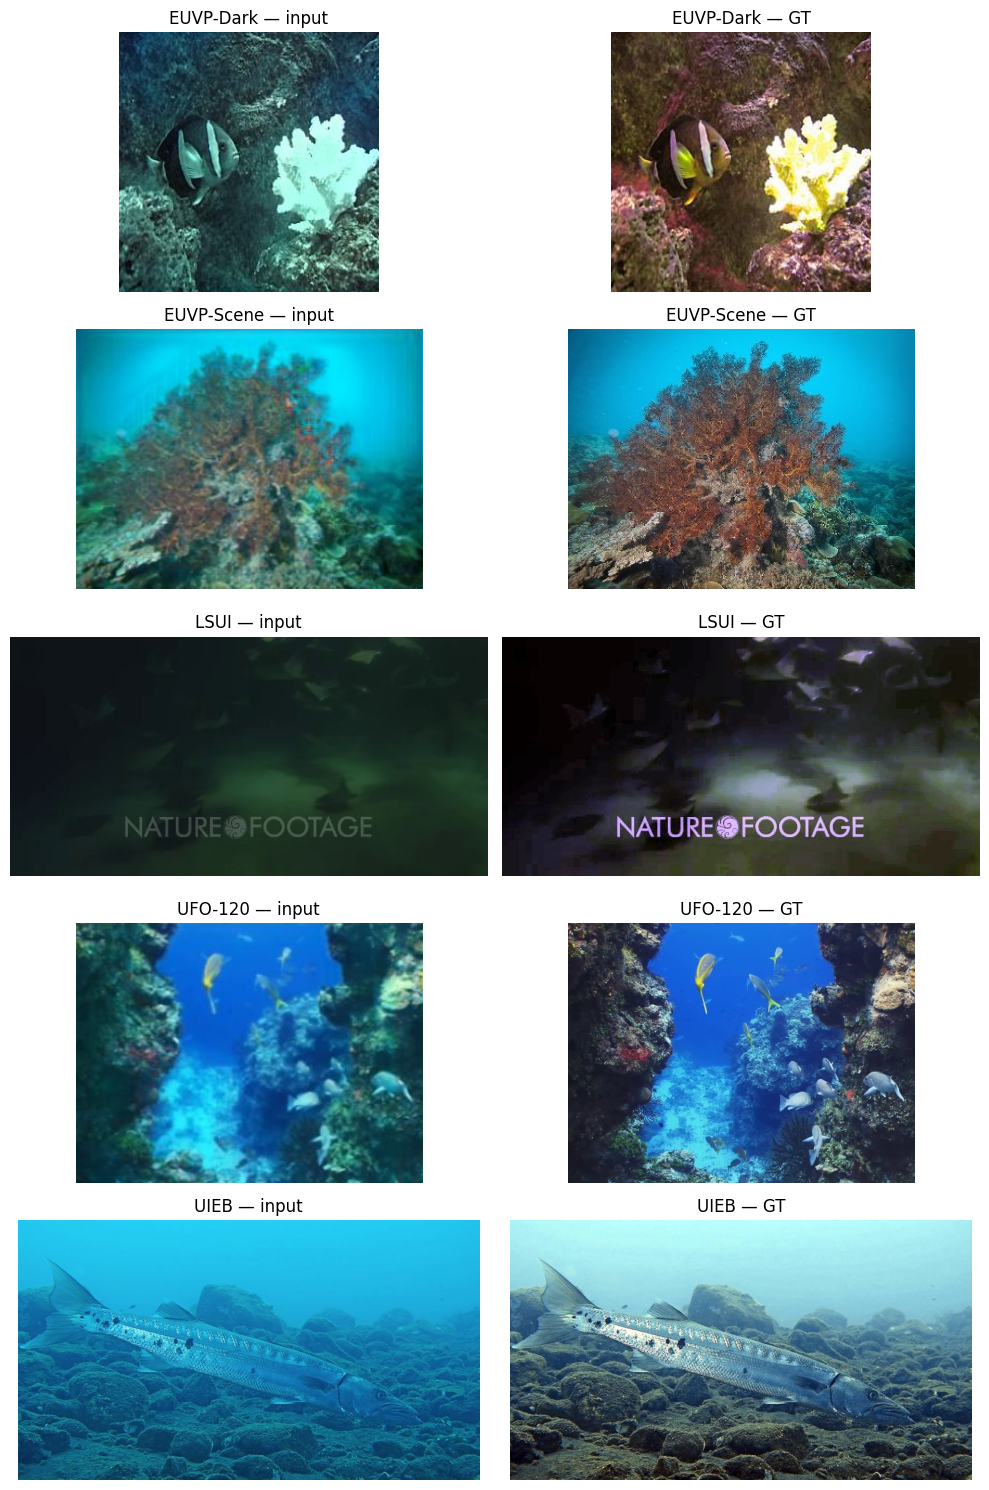

In [4]:
fig, axes = plt.subplots(len(FOLDERS), 2, figsize=(10, 3 * len(FOLDERS)))
for row, name in enumerate(FOLDERS):
    item = samples[(samples.dataset == name) & (samples.split == 'train')].iloc[0]
    for column, key in enumerate(['input', 'target']):
        axes[row, column].imshow(Image.open(item[key]).convert('RGB'))
        axes[row, column].set_title(name + (' — input' if key == 'input' else ' — GT'))
        axes[row, column].axis('off')
plt.tight_layout(); display(fig); plt.close(fig)


## 5. DataLoader

Ảnh được resize về 256×256 để ghép batch giữa các bộ dữ liệu. Preprocessing và augmentation dùng chung với pipeline xử lý ảnh.

In [5]:
datasets = {split: {} for split in ['train', 'val', 'test']}
for split in datasets:
    for name in FOLDERS:
        original = DatasetFromFolder(str(DATA_ROOT / name / split), IMAGE_SIZE, train=split == 'train', resize=True)
        allowed = set(samples[(samples.dataset == name) & (samples.split == split)].input)
        indices = [i for i, path in enumerate(original.data_filenames) if path in allowed]
        assert indices, f'Split rỗng: {name}/{split}'
        datasets[split][name] = Subset(original, indices)
train_dataset = ConcatDataset(list(datasets['train'].values()))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loaders = {name: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0) for name, ds in datasets['val'].items()}
test_loaders = {name: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0) for name, ds in datasets['test'].items()}
print('Train images:', len(train_dataset), '| batches/epoch:', len(train_loader))
print('Validation:', {name: len(loader.dataset) for name, loader in val_loaders.items()})
print('Test (chưa sử dụng):', {name: len(loader.dataset) for name, loader in test_loaders.items()})


Train images: 11089 | batches/epoch: 2773
Validation: {'EUVP-Dark': 550, 'EUVP-Scene': 218, 'LSUI': 419, 'UFO-120': 274, 'UIEB': 89}
Test (chưa sử dụng): {'EUVP-Dark': 555, 'EUVP-Scene': 219, 'LSUI': 428, 'UFO-120': 120, 'UIEB': 89}


## 6. Model and Loss Networks


In [6]:
seed_everything(SEED)
model = myModel(in_channels=3, feature_channels=32, use_white_balance=True).to(DEVICE)
if not RESUME_FROM: torch.save(model.state_dict(), RUN_DIR / 'initial_model.pth')
hvi_net = CIDNet().to(DEVICE)
hvi_net.load_state_dict(torch.load(ROOT / 'utils/CIDNet_weight_LOLv2_bestSSIM.pth', map_location=DEVICE, weights_only=True))
hvi_net.eval().requires_grad_(False)
vgg_loss_fn = PerceptualLoss().eval()
l1_loss_fn = L1_Charbonnier_loss()
ssim_loss_fn = SSIMLoss(device='cuda', window_size=5)
edge_loss_fn = EdgeAwareLoss(loss_type='l2', device='cuda')
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.999))
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS, eta_min=LR * 1e-4)
print('Số tham số:', f'{sum(p.numel() for p in model.parameters()):,}')
print('Khởi tạo: RANDOM, seed', SEED, '| optimizer step:', len(optimizer.state))
assert len(optimizer.state) == 0


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to D:\xulyanh_ttnt1\UNDERWATER-IMAGING\downloads\torch\checkpoints\vgg16-397923af.pth


  0%|          | 0.00/528M [00:00<?, ?B/s]

  0%|          | 768k/528M [00:00<01:13, 7.56MB/s]

  1%|▏         | 7.62M/528M [00:00<00:12, 44.8MB/s]

  2%|▏         | 12.0M/528M [00:00<00:14, 37.7MB/s]

...

 95%|█████████▍| 501M/528M [00:04<00:00, 116MB/s]

 97%|█████████▋| 512M/528M [00:04<00:00, 115MB/s]

 99%|█████████▉| 524M/528M [00:05<00:00, 116MB/s]

100%|██████████| 528M/528M [00:05<00:00, 110MB/s]

Số tham số: 734,059
Khởi tạo: RANDOM, seed 7 | optimizer step: 0


## 7. Loss Functions


In [7]:
def compute_loss(pred, label):
    with torch.no_grad():
        label_hvi = hvi_net.trans.HVIT(label)
    pred_hvi = hvi_net.trans.HVIT(pred.clamp(0.0, 1.0))
    parts = dict(l1=l1_loss_fn(pred, label), hvi=l1_loss_fn(pred_hvi, label_hvi),
                 ssim=ssim_loss_fn(pred, label), vgg=vgg_loss_fn(pred, label), edge=edge_loss_fn(pred, label))
    total = parts['l1'] + 0.5 * parts['hvi'] + 0.1 * parts['ssim'] + 0.1 * parts['vgg'] + 0.1 * parts['edge']
    return total, parts


## 8. Gradient and GPU Memory Check


In [8]:
rng = (random.getstate(), np.random.get_state(), torch.get_rng_state(), torch.cuda.get_rng_state_all())
x, target, _ = next(iter(train_loader))
x, target = x.to(DEVICE), target.to(DEVICE)
torch.cuda.reset_peak_memory_stats()
model.train()
prediction = model(x)
loss, parts = compute_loss(prediction, target)
assert torch.isfinite(loss), 'Loss không hữu hạn'
loss.backward()
assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
optimizer.zero_grad(set_to_none=True)
print('Shape:', tuple(prediction.shape), '| loss:', float(loss.detach()))
print('Loss components:', {name: float(value.detach()) for name, value in parts.items()})
print('Peak GPU memory:', round(torch.cuda.max_memory_allocated() / 1024**2), 'MiB')
del x, target, prediction, loss, parts
random.setstate(rng[0]); np.random.set_state(rng[1]); torch.set_rng_state(rng[2]); torch.cuda.set_rng_state_all(rng[3])
torch.cuda.empty_cache()


Shape: (4, 3, 256, 256) | loss: 0.362736314535141
Loss components: {'l1': 0.13408228754997253, 'hvi': 0.2632833421230316, 'ssim': 0.3845091462135315, 'vgg': 0.5469706058502197, 'edge': 0.03864380344748497}
Peak GPU memory: 2915 MiB


## 9. Validation and Checkpoints


In [9]:
history = []
best_psnr = float('-inf')
best_epoch = 0
status = dict(dataset='ALL', epochs=EPOCHS, epoch=0, run_path=str(RUN_DIR.relative_to(ROOT)),
              state='preparing', initialization='random', detail='Fresh notebook training; no previous checkpoint loaded.')

START_EPOCH = 1
if RESUME_FROM:
    saved = torch.load(RESUME_FROM, map_location=DEVICE, weights_only=False)
    model.load_state_dict(saved['model'])
    optimizer.load_state_dict(saved['optimizer'])
    scheduler.load_state_dict(saved['scheduler'])
    history = list(saved['history']) if 'history' in saved else \
        pd.read_csv(RUN_DIR / 'history.csv').query('epoch <= @saved["epoch"]').to_dict('records')
    best_psnr, best_epoch, START_EPOCH = saved['best_psnr'], saved['best_epoch'], saved['epoch'] + 1
    random.setstate(saved['python_rng']); np.random.set_state(saved['numpy_rng'])
    torch.set_rng_state(saved['torch_rng'].cpu()); torch.cuda.set_rng_state_all([s.cpu() for s in saved['cuda_rng']])
    status.update(initialization='resume', detail=f'Resumed from {RESUME_FROM.name} (epoch {saved["epoch"]}).')
    print('Resume:', RESUME_FROM, '| epoch tiếp theo:', START_EPOCH, '| best epoch:', best_epoch)
    del saved

def update_status(**values):
    status.update(values)
    target = ROOT / 'output/training_status.json'
    temp = target.with_suffix('.tmp')
    temp.write_text(json.dumps(status), encoding='utf-8')
    try: replace_with_retry(temp, target)
    except PermissionError: pass

def save_weights(name):
    path = RUN_DIR / name
    temporary = path.with_suffix('.tmp')
    torch.save(model.state_dict(), temporary)
    replace_with_retry(temporary, path)

@torch.inference_mode()
def evaluate(loader):
    evaluator = Evaluator()
    model.eval()
    for images, labels, _ in loader:
        pred = model(images.to(DEVICE)).clamp(0, 1).cpu().numpy().transpose(0, 2, 3, 1)
        evaluator.evaluation(pred, labels.numpy().transpose(0, 2, 3, 1))
    ssim, psnr = evaluator.getMean()
    return dict(psnr=float(psnr), ssim=float(ssim), images=len(loader.dataset))

def plot_history():
    table = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    for axis, key, title in zip(axes, ['loss', 'psnr', 'ssim'], ['Train loss', 'Macro validation PSNR', 'Macro validation SSIM']):
        axis.plot(table.epoch, table[key], color='#16726d')
        axis.set_title(title); axis.set_xlabel('Epoch'); axis.grid(alpha=0.2)
    fig.tight_layout(); fig.savefig(RUN_DIR / 'curves.png', dpi=130)
    return fig

@torch.inference_mode()
def preview():
    fixed = samples[(samples.dataset == 'UIEB') & (samples.split == 'val')].iloc[0]
    image = Image.open(fixed.input).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
    gt = Image.open(fixed.target).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
    tensor = torch.from_numpy(np.array(image).astype(np.float32) / 255).permute(2, 0, 1)[None].to(DEVICE)
    result = model(tensor).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for axis, value, title in zip(axes, [image, result, gt], ['Input', 'Mô hình mới', 'Ground truth']):
        axis.imshow(value); axis.set_title(title); axis.axis('off')
    fig.tight_layout(); fig.savefig(RUN_DIR / 'latest_preview.png', dpi=130)
    return fig

update_status()
print('Checkpoint sẽ chỉ được ghi vào:', RUN_DIR)
print('Checkpoint từng epoch:', CHECKPOINT_DIR)


Checkpoint sẽ chỉ được ghi vào: D:\xulyanh_ttnt1\UNDERWATER-IMAGING\output\demo\ALL\notebook_20261016_205330
Checkpoint từng epoch: D:\xulyanh_ttnt1\UNDERWATER-IMAGING\output\demo\ALL\notebook_20261016_205330\checkpoints


## 10. Training

Batch 4, tích lũy gradient 6 bước, tương đương batch 24. Nhóm cuối được chuẩn hóa theo số ảnh thực tế.

Checkpoint tốt nhất được chọn bằng macro PSNR trên validation của năm bộ dữ liệu. Sau mỗi epoch, trạng thái đầy đủ (model, optimizer, scheduler, RNG, history) được giữ riêng tại `checkpoints/epoch_XXX.pth`.

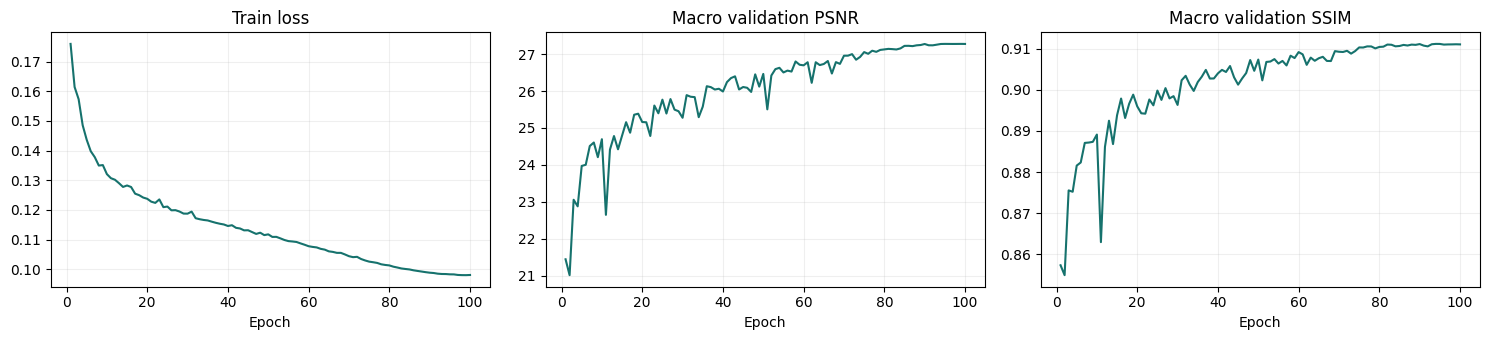

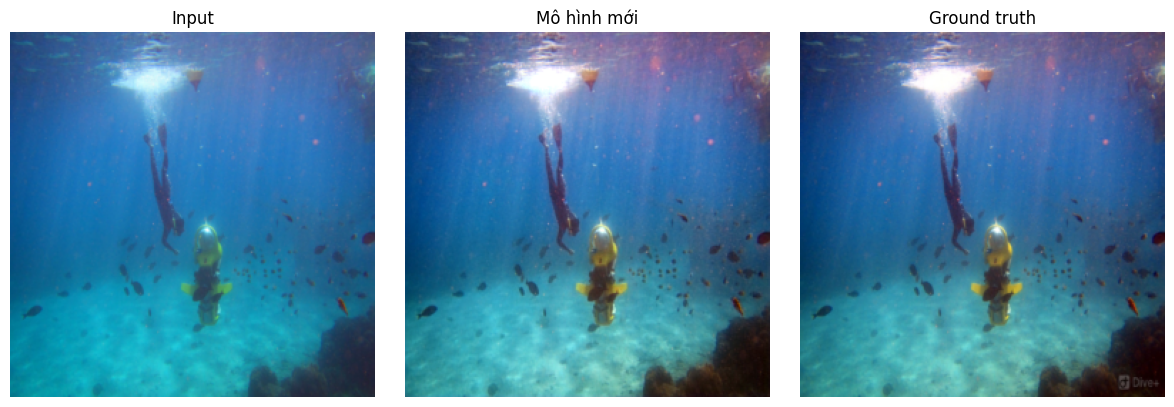

,psnr,ssim,images
EUVP-Dark,22.6860,0.9099,550.0
EUVP-Scene,29.9628,0.9074,218.0
LSUI,30.1055,0.9329,419.0
UFO-120,30.1973,0.9103,274.0
UIEB,23.4211,0.8946,89.0


Tổng thời gian: 17.1 giờ


,epoch,loss,psnr,ssim,lr,seconds,EUVP-Dark_psnr,EUVP-Dark_ssim,EUVP-Scene_psnr,EUVP-Scene_ssim,LSUI_psnr,LSUI_ssim,UFO-120_psnr,UFO-120_ssim,UIEB_psnr,UIEB_ssim
0,1,0.175934,21.447200,0.857347,2.000000e-03,1417.098095,20.378653,0.878968,23.405078,0.849879,21.127926,0.865745,23.655323,0.859020,18.669020,0.833121
1,2,0.161402,21.017530,0.854944,1.999507e-03,1528.454666,18.767914,0.869145,23.088684,0.849646,20.662343,0.865168,23.407905,0.854356,19.160805,0.836407
2,3,0.157289,23.057911,0.875536,1.998027e-03,589.612256,21.245572,0.893014,25.528916,0.869872,23.267795,0.888568,25.671503,0.873247,19.575769,0.852979
3,4,0.148528,22.879680,0.875204,1.995562e-03,590.582767,21.253865,0.895570,24.643389,0.864904,23.167367,0.887344,24.891464,0.869245,20.442313,0.858957
4,5,0.143619,23.973158,0.881559,1.992115e-03,590.385665,22.068743,0.896655,26.457472,0.875433,24.323322,0.897123,26.732051,0.881601,20.284203,0.856983
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,0.098258,27.275169,0.910956,1.251043e-05,598.120918,22.693028,0.909902,29.972436,0.907287,30.097969,0.932866,30.198030,0.910249,23.414382,0.894475
96,97,0.098069,27.274330,0.910995,8.084510e-06,596.277475,22.688060,0.909912,29.963423,0.907349,30.103627,0.932891,30.192792,0.910237,23.423746,0.894587
97,98,0.098013,27.274797,0.911005,4.637592e-06,597.404183,22.685699,0.909892,29.962088,0.907380,30.104877,0.932896,30.196670,0.910253,23.424653,0.894606
98,99,0.098000,27.275887,0.911033,2.173074e-06,593.671580,22.685674,0.909855,29.963186,0.907420,30.101225,0.932890,30.194621,0.910277,23.434731,0.894722


In [10]:
live = display(HTML('Bắt đầu lượt train mới…' if START_EPOCH == 1 else f'Tiếp tục từ epoch {START_EPOCH}…'), display_id=True)
curves = display(HTML('Biểu đồ xuất hiện sau epoch đầu.'), display_id=True)
images_view = display(HTML('Ảnh dự đoán xuất hiện sau validation đầu.'), display_id=True)
metrics_view = display(HTML('Chưa có chỉ số validation.'), display_id=True)
start = time.perf_counter()
try:
    for epoch in range(START_EPOCH, EPOCHS + 1):
        epoch_start = time.perf_counter()
        model.train(); optimizer.zero_grad(set_to_none=True)
        sum_loss, seen = 0.0, 0
        update_status(state='training', epoch=epoch, steps=len(train_loader), step=0)
        for step, (images, labels, _) in enumerate(train_loader):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            pred = model(images)
            loss, components = compute_loss(pred, labels)
            if not torch.isfinite(loss): raise RuntimeError(f'Loss không hữu hạn ở epoch {epoch}, batch {step + 1}')
            group_start = (step // ACCUMULATION) * ACCUMULATION * BATCH_SIZE
            group_images = min(EFFECTIVE_BATCH, len(train_dataset) - group_start)
            (loss * images.size(0) / group_images).backward()
            if (step + 1) % ACCUMULATION == 0 or step + 1 == len(train_loader):
                optimizer.step(); optimizer.zero_grad(set_to_none=True)
            sum_loss += float(loss.detach()) * images.size(0); seen += images.size(0)
            if step % 20 == 0 or step + 1 == len(train_loader):
                detail = f'Epoch {epoch}/{EPOCHS} · batch {step + 1}/{len(train_loader)} · loss {float(loss.detach()):.4f}'
                live.update(HTML('<b>' + detail + '</b>'))
                update_status(step=step + 1, loss=float(loss.detach()), detail=detail)
        update_status(state='validating', detail='Validation trên từng bộ, không dùng test.')
        per_dataset = {name: evaluate(loader) for name, loader in val_loaders.items()}
        macro_psnr = float(np.mean([row['psnr'] for row in per_dataset.values()]))
        macro_ssim = float(np.mean([row['ssim'] for row in per_dataset.values()]))
        row = dict(epoch=epoch, loss=sum_loss / seen, psnr=macro_psnr, ssim=macro_ssim,
                   lr=optimizer.param_groups[0]['lr'], seconds=time.perf_counter() - epoch_start)
        for name, values in per_dataset.items():
            row[name + '_psnr'] = values['psnr']; row[name + '_ssim'] = values['ssim']
        history.append(row)
        pd.DataFrame(history).to_csv(RUN_DIR / 'history.csv', index=False)
        if macro_psnr > best_psnr:
            best_psnr, best_epoch = macro_psnr, epoch
            save_weights('best_model.pth')
        scheduler.step()
        save_weights('last_model.pth')
        checkpoint = dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                          epoch=epoch, best_psnr=best_psnr, best_epoch=best_epoch, config=config, history=history,
                          python_rng=random.getstate(), numpy_rng=np.random.get_state(),
                          torch_rng=torch.get_rng_state(), cuda_rng=torch.cuda.get_rng_state_all())
        tmp = CHECKPOINT_DIR / f'epoch_{epoch:03d}.tmp'; torch.save(checkpoint, tmp)
        replace_with_retry(tmp, CHECKPOINT_DIR / f'epoch_{epoch:03d}.pth')
        tmp = RUN_DIR / 'last_checkpoint.tmp'; torch.save(checkpoint, tmp)
        replace_with_retry(tmp, RUN_DIR / 'last_checkpoint.pth')
        update_status(loss=row['loss'], psnr=macro_psnr, ssim=macro_ssim, best_epoch=best_epoch,
                      detail=f'Epoch {epoch} hoàn tất; macro validation PSNR {macro_psnr:.2f} dB.')
        fig = plot_history(); curves.update(fig); plt.close(fig)
        fig = preview(); images_view.update(fig); plt.close(fig)
        metrics_view.update(HTML(pd.DataFrame(per_dataset).T.round(4).to_html()))
        live.update(HTML(f'<b>Đã hoàn tất epoch {epoch}/{EPOCHS}</b> · {row["seconds"]:.1f} giây/epoch · best epoch {best_epoch}'))
    update_status(state='training_complete', epoch=EPOCHS, detail='Đã hoàn tất train; chạy cell test tiếp theo để nghiệm thu.')
except BaseException as error:
    update_status(state='interrupted' if isinstance(error, KeyboardInterrupt) else 'failed', detail=str(error))
    raise
finally:
    training_lock.seek(0)
    msvcrt.locking(training_lock.fileno(), msvcrt.LK_UNLCK, 1)
    training_lock.close()
print('Tổng thời gian:', round((time.perf_counter() - start) / 3600, 2), 'giờ')
display(pd.DataFrame(history))


## 11. Test

Đánh giá checkpoint tốt nhất của lượt huấn luyện trên test split giữ riêng.

,psnr,ssim,images
EUVP-Dark,22.7827,0.9101,555.0
EUVP-Scene,29.9250,0.9049,219.0
LSUI,30.2542,0.9298,428.0
UFO-120,30.1463,0.9040,120.0
UIEB,23.3740,0.8997,89.0


Macro test PSNR: 27.29645317155478
Macro test SSIM: 0.9096833592039477
Best checkpoint: D:\xulyanh_ttnt1\UNDERWATER-IMAGING\output\demo\ALL\notebook_20261016_205330\best_model.pth


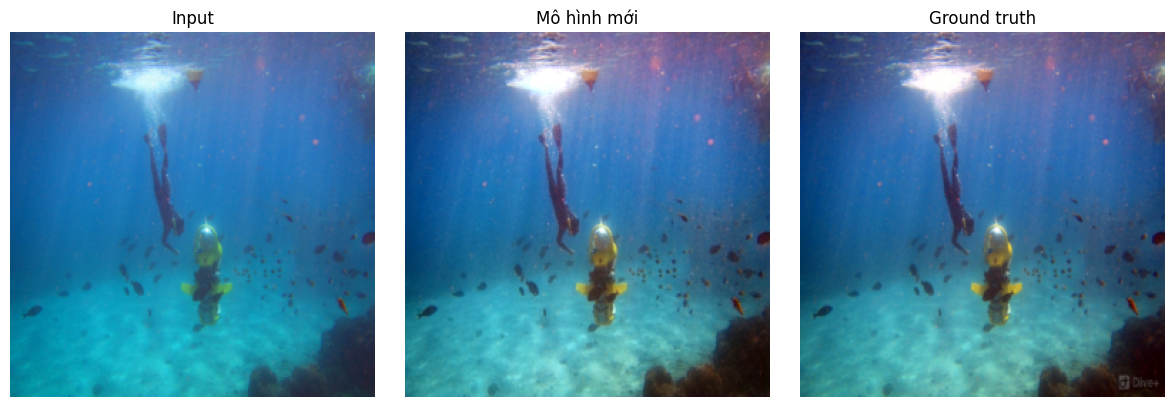

In [11]:
assert len(history) == EPOCHS, 'Chưa hoàn tất training; không dùng test để chọn tham số.'
model.load_state_dict(torch.load(RUN_DIR / 'best_model.pth', map_location=DEVICE, weights_only=True))
test_results = pd.DataFrame({name: evaluate(loader) for name, loader in test_loaders.items()}).T
test_results.to_csv(RUN_DIR / 'test_results.csv')
display(test_results.round(4))
print('Macro test PSNR:', float(test_results.psnr.mean()))
print('Macro test SSIM:', float(test_results.ssim.mean()))
print('Best checkpoint:', RUN_DIR / 'best_model.pth')
fig = preview(); display(fig); plt.close(fig)

update_status(state='complete', detail='Đã hoàn tất train và test trong VS Code.', test_results=str(RUN_DIR / 'test_results.csv'))


## 12. Results

| File | Description |
|---|---|
| `config.json`, `data_manifest.csv` | Cấu hình và danh sách cặp ảnh |
| `history.csv`, `curves.png` | Loss và validation theo epoch, theo bộ dữ liệu |
| `initial_model.pth` | Trọng số khởi tạo |
| `best_model.pth`, `last_model.pth` | Trọng số tốt nhất và cuối cùng |
| `last_checkpoint.pth` | Trạng thái huấn luyện |
| `checkpoints/epoch_XXX.pth` | Trạng thái huấn luyện đầy đủ của từng epoch |
| `test_results.csv` | Chỉ số trên test split |
